In [1]:
# Bloco código 1
# Lê o log (inclusive arquivos já rotacionados) e mostra um resumo do volume
from pathlib import Path

import pandas as pd

# O VS Code executa o notebook a partir da pasta notebooks/; o log fica na raiz do projeto
ROOT = Path.cwd() if (Path.cwd() / "logs").exists() else Path.cwd().parent
LOG_DIR = ROOT / "logs"

# inference.jsonl (atual) + inference.jsonl.1, .2 ... (rotacionados); o .lock é ignorado
files = sorted(p for p in LOG_DIR.glob("inference.jsonl*") if not p.name.endswith(".lock"))
df = pd.concat([pd.read_json(f, lines=True, dtype={"request_id": str}) for f in files], ignore_index=True)
df["ts"] = pd.to_datetime(df["ts"], format="ISO8601")  # mantém o fuso (-03:00)
df = df.sort_values("ts").reset_index(drop=True)

print("Arquivos lidos:", [f.name for f in files])
print("Linhas:", len(df), "| Colunas:", df.shape[1])
print("Período:", df["ts"].min(), "->", df["ts"].max())
df.groupby(["scenario", "status"]).size().unstack(fill_value=0)

Arquivos lidos: ['inference.jsonl']
Linhas: 920 | Colunas: 33
Período: 2026-11-17 23:21:16.260680-03:00 -> 2026-11-17 23:28:13.887789-03:00


status,error,ok
scenario,,
drift,8,292
normal,15,305
reference,6,294


In [2]:
# Bloco código 2
# Critérios de suficiência do CRISP-DM: completude, unicidade e volume
INPUT_NUM = ["file_bytes", "width", "height", "aspect_ratio", "mean_L", "std_L",
             "mean_R", "mean_G", "mean_B", "sharpness", "colorfulness"]
OUTPUT_NUM = ["top1_score", "margin_top1_top2", "entropy", "features_ms", "inference_ms", "latency_ms"]
CATEG = ["img_format", "img_mode", "exif_rotated", "top1_label"]

ok = df[df["status"] == "ok"]
err = df[df["status"] == "error"]

checks = pd.Series({
    "Campos nulos nas linhas de sucesso (esperado 0)": int(ok[INPUT_NUM + OUTPUT_NUM + CATEG].isna().sum().sum()),
    "Erros sem error_type (esperado 0)": int(err["error_type"].isna().sum()),
    "request_id repetidos (esperado 0)": int(df["request_id"].duplicated().sum()),
    "Menor volume de sucessos por cenário (mínimo 200)": int(ok.groupby("scenario").size().min()),
})
display(checks.to_frame("valor"))

# Taxa de erro por cenário e causa: base da pergunta P3 (saúde operacional)
display(err.groupby(["scenario", "http_status", "error_type"]).size().to_frame("pedidos"))
print(f"Taxa de erro geral: {len(err) / len(df):.1%}")

,valor
Campos nulos nas linhas de sucesso (esperado 0),0
Erros sem error_type (esperado 0),0
request_id repetidos (esperado 0),0
Menor volume de sucessos por cenário (mínimo 200),292


pedidos
scenario  http_status error_type               
drift     400         invalid_image           5
                      validation_error        3
normal    400         invalid_image          12
                      validation_error        3
reference 400         invalid_image           2
                      validation_error        4

Taxa de erro geral: 3.2%


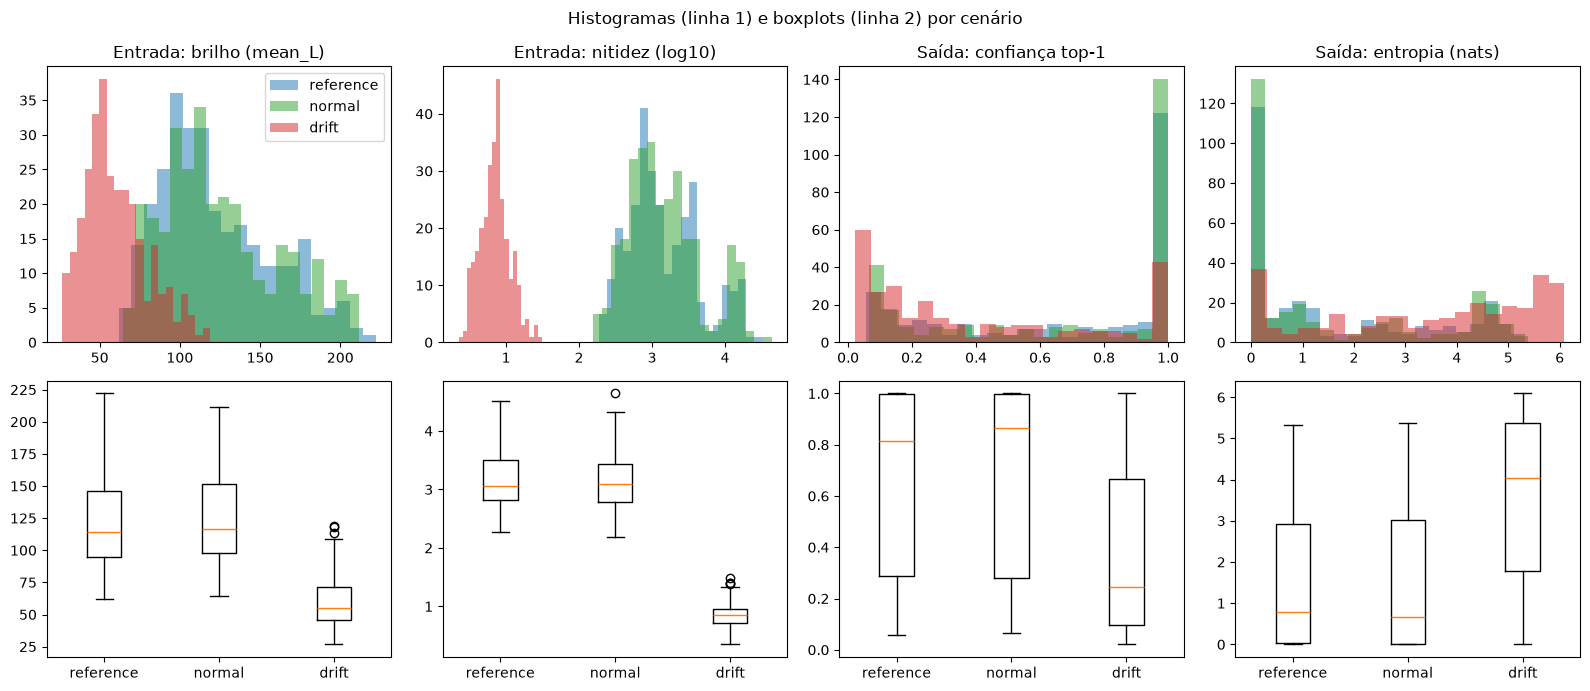

In [3]:
# Bloco código 3
# Histogramas (linha 1) e boxplots (linha 2): 2 variáveis de ENTRADA e 2 de SAÍDA, por cenário
import matplotlib.pyplot as plt
import numpy as np

SCEN = ["reference", "normal", "drift"]
COLORS = {"reference": "tab:blue", "normal": "tab:green", "drift": "tab:red"}
VARS = {  # coluna -> título
    "mean_L": "Entrada: brilho (mean_L)",
    "sharpness": "Entrada: nitidez (log10)",
    "top1_score": "Saída: confiança top-1",
    "entropy": "Saída: entropia (nats)",
}


def values(col: str, scenario: str) -> pd.Series:
    v = ok.loc[ok["scenario"] == scenario, col]
    # Nitidez vai de ~5 a ~50.000: em escala log10 as diferenças ficam visíveis
    return np.log10(v + 1) if col == "sharpness" else v


fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for j, (col, title) in enumerate(VARS.items()):
    for s in SCEN:
        axes[0, j].hist(values(col, s), bins=20, alpha=0.5, color=COLORS[s], label=s)
    axes[0, j].set_title(title)
    axes[1, j].boxplot([values(col, s) for s in SCEN], tick_labels=SCEN)
axes[0, 0].legend()
fig.suptitle("Histogramas (linha 1) e boxplots (linha 2) por cenário")
fig.tight_layout()
plt.show()

In [4]:
# Bloco código 4
# KS e PSI de todas as variáveis numéricas: "reference" contra "normal" e contra "drift"
from scipy.stats import ks_2samp

EPS = 1e-4  # evita log(0) quando uma faixa fica vazia


def psi_numeric(ref: np.ndarray, cur: np.ndarray, bins: int = 10) -> float:
    """PSI com faixas definidas pelos decis da REFERÊNCIA (cada faixa tem ~10% da referência)."""
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf  # valores fora da faixa da referência também contam
    p = np.clip(np.histogram(ref, edges)[0] / len(ref), EPS, None)
    q = np.clip(np.histogram(cur, edges)[0] / len(cur), EPS, None)
    return float(np.sum((q - p) * np.log(q / p)))


def psi_categorical(ref: pd.Series, cur: pd.Series, top: int = 10) -> float:
    """PSI para categorias: as `top` mais frequentes da referência; o resto vira "outras"."""
    keep = ref.value_counts().index[:top]
    ref, cur = ref.where(ref.isin(keep), "outras"), cur.where(cur.isin(keep), "outras")
    cats = sorted(set(ref) | set(cur))
    p = ref.value_counts(normalize=True).reindex(cats, fill_value=0).clip(lower=EPS)
    q = cur.value_counts(normalize=True).reindex(cats, fill_value=0).clip(lower=EPS)
    return float(((q - p) * np.log(q / p)).sum())


ref = ok[ok["scenario"] == "reference"]
rows = []
for col in INPUT_NUM + OUTPUT_NUM:
    row = {"variável": col}
    for s in ["normal", "drift"]:
        cur = ok[ok["scenario"] == s]
        ks = ks_2samp(ref[col], cur[col])
        row[f"KS {s}"], row[f"p {s}"] = ks.statistic, ks.pvalue
        row[f"PSI {s}"] = psi_numeric(ref[col].to_numpy(), cur[col].to_numpy())
    rows.append(row)
rows.append({"variável": "top1_label (top-10 + outras)",
             **{f"PSI {s}": psi_categorical(ref["top1_label"], ok.loc[ok["scenario"] == s, "top1_label"])
                for s in ["normal", "drift"]}})

res = pd.DataFrame(rows).set_index("variável")
res["alerta drift (PSI > 0,25)"] = res["PSI drift"] > 0.25
res.round(3)

,KS normal,p normal,PSI normal,KS drift,p drift,PSI drift,"alerta drift (PSI > 0,25)"
variável,,,,,,,
file_bytes,0.078,0.297,0.038,0.925,0.000,8.244,True
width,0.076,0.329,0.055,0.056,0.714,0.027,False
height,0.059,0.641,0.059,0.064,0.552,0.057,False
aspect_ratio,0.055,0.730,0.053,0.065,0.540,0.093,False
mean_L,0.080,0.267,0.061,0.768,0.000,5.040,True
std_L,0.041,0.947,0.028,0.894,0.000,7.166,True
mean_R,0.078,0.295,0.077,0.744,0.000,4.454,True
mean_G,0.087,0.194,0.072,0.802,0.000,5.254,True
mean_B,0.078,0.302,0.078,0.639,0.000,4.107,True


## Conclusão da verificação

**Formato:** o JSON Lines é lido diretamente pelo pandas (`read_json(lines=True)`), inclusive somando
arquivos rotacionados; o `ts` preserva microssegundos e fuso. Formato adequado.

**Suficiência:** 0 campos nulos nas linhas de sucesso, 0 erros sem causa, 0 `request_id` repetidos e
pelo menos 292 sucessos por cenário (mínimo definido: 200). Dados suficientes para histogramas,
boxplots, KS e PSI.

**Poder de detecção:**
- `reference` × `normal` (mesma distribuição): PSI < 0,1 em todas as variáveis de dados, sem alarme falso;
- `reference` × `drift` (imagens escuras, borradas e desbotadas): PSI de 4 a 8 nas entradas de imagem,
  enquanto a geometria, que não foi alterada, segue estável; as métricas são sensíveis e específicas;
- o drift de entrada degradou o modelo: a mediana da confiança caiu de cerca de 0,8 para 0,25 e a da
  entropia subiu de cerca de 0,7 para 4,0. As variáveis de saída capturam esse efeito.

**Ressalva:** `latency_ms` e `inference_ms` variam com o estado da máquina (aquecimento, carga
concorrente) e acusam diferença até entre cenários equivalentes. Latência deve ser monitorada por
limites absolutos (ex.: p95) e pelo `/metrics`, não por drift contra uma referência.